In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
from google.colab import files

uploaded = files.upload()

Saving weather_data.csv to weather_data.csv


In [5]:
hospital = pd.read_csv("hospital_patient_data.csv")
weather = pd.read_csv("weather_data.csv")
air_quality = pd.read_csv("air_quality_data.csv")

print("Hospital Data:")
display(hospital.head())

print("\nWeather Data:")
display(weather.head())

print("\nAir Quality Data:")
display(air_quality.head())

Hospital Data:


,male_op_0_15,female_op_0_15,male_ev_0_15,female_ev_0_15,male_opev_0_15,female_opev_0_15,male_op_16_65,female_op_16_65,male_ev_16_65,female_ev_16_65,...,male_op_65plus,female_op_65plus,male_ev_65plus,female_ev_65plus,male_opev_65plus,female_opev_65plus,Date,Outpatient_Count,Emergency_Count,Total_Patient_Count
0,16,0,5,3,21,3,47,31,14,8,...,8,7,1,0,9,7,2007-01-01,109,31,140
1,13,6,7,3,20,9,64,36,18,11,...,5,11,3,1,8,12,2007-01-02,135,43,178
2,16,6,2,1,18,7,57,31,12,6,...,5,6,0,0,5,6,2007-01-03,121,21,142
3,19,8,5,5,24,13,53,46,17,13,...,6,8,0,0,6,8,2007-01-04,140,40,180
4,17,8,3,3,20,11,56,47,13,6,...,3,7,3,3,6,10,2007-01-05,138,31,169



Weather Data:


,Date,Temperature_C,Rainfall_mm,Humidity_pct,Wind_Speed_mps,Wind_Direction_deg
0,2007-01-01,21.45,0.0,77.67,2.35,17.0
1,2007-01-02,22.36,0.0,72.25,3.88,2.0
2,2007-01-03,19.93,33.6,83.38,2.85,2.0
3,2007-01-04,17.18,6.4,82.84,3.44,2.0
4,2007-01-05,16.33,0.0,77.95,2.75,2.0



Air Quality Data:


,Date,PM10_ug_m3,PM25_ug_m3,CO_ppmv,NO_ppbv,NO2_ppbv,O3_ppbv,SO2_ppbv
0,2007-01-01,79.0,49.0,2.25,69.65,34.20,27.2,7.7
1,2007-01-02,43.0,17.0,0.69,13.88,30.35,26.2,8.8
2,2007-01-03,45.0,25.0,1.20,50.63,44.44,29.3,7.7
3,2007-01-04,72.0,42.0,1.17,22.67,30.63,26.5,8.7
4,2007-01-05,92.0,54.0,1.62,47.48,44.78,23.6,12.2


In [6]:
print("Hospital shape:", hospital.shape)
print("Weather shape:", weather.shape)
print("Air Quality shape:", air_quality.shape)

Hospital shape: (1826, 22)
Weather shape: (1826, 6)
Air Quality shape: (1826, 8)


In [7]:
print("Hospital columns:")
print(hospital.columns.tolist())

print("\nWeather columns:")
print(weather.columns.tolist())

print("\nAir Quality columns:")
print(air_quality.columns.tolist())

Hospital columns:
['male_op_0_15', 'female_op_0_15', 'male_ev_0_15', 'female_ev_0_15', 'male_opev_0_15', 'female_opev_0_15', 'male_op_16_65', 'female_op_16_65', 'male_ev_16_65', 'female_ev_16_65', 'male_opev_16_65', 'female_opev_16_65', 'male_op_65plus', 'female_op_65plus', 'male_ev_65plus', 'female_ev_65plus', 'male_opev_65plus', 'female_opev_65plus', 'Date', 'Outpatient_Count', 'Emergency_Count', 'Total_Patient_Count']

Weather columns:
['Date', 'Temperature_C', 'Rainfall_mm', 'Humidity_pct', 'Wind_Speed_mps', 'Wind_Direction_deg']

Air Quality columns:
['Date', 'PM10_ug_m3', 'PM25_ug_m3', 'CO_ppmv', 'NO_ppbv', 'NO2_ppbv', 'O3_ppbv', 'SO2_ppbv']


In [8]:
print("\nHospital information:")
hospital.info()

print("\nWeather information:")
weather.info()

print("\nAir Quality information:")
air_quality.info()


Hospital information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1826 entries, 0 to 1825
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   male_op_0_15         1826 non-null   int64 
 1   female_op_0_15       1826 non-null   int64 
 2   male_ev_0_15         1826 non-null   int64 
 3   female_ev_0_15       1826 non-null   int64 
 4   male_opev_0_15       1826 non-null   int64 
 5   female_opev_0_15     1826 non-null   int64 
 6   male_op_16_65        1826 non-null   int64 
 7   female_op_16_65      1826 non-null   int64 
 8   male_ev_16_65        1826 non-null   int64 
 9   female_ev_16_65      1826 non-null   int64 
 10  male_opev_16_65      1826 non-null   int64 
 11  female_opev_16_65    1826 non-null   int64 
 12  male_op_65plus       1826 non-null   int64 
 13  female_op_65plus     1826 non-null   int64 
 14  male_ev_65plus       1826 non-null   int64 
 15  female_ev_65plus     1826 non-nu

In [9]:
hospital["Date"] = pd.to_datetime(hospital["Date"], errors="coerce")
weather["Date"] = pd.to_datetime(weather["Date"], errors="coerce")
air_quality["Date"] = pd.to_datetime(air_quality["Date"], errors="coerce")

print("Hospital date range:")
print(hospital["Date"].min(), "to", hospital["Date"].max())

print("\nWeather date range:")
print(weather["Date"].min(), "to", weather["Date"].max())

print("\nAir quality date range:")
print(air_quality["Date"].min(), "to", air_quality["Date"].max())

Hospital date range:
2007-01-01 00:00:00 to 2011-12-31 00:00:00

Weather date range:
2007-01-01 00:00:00 to 2011-12-31 00:00:00

Air quality date range:
2007-01-01 00:00:00 to 2011-12-31 00:00:00


In [10]:
print("Hospital missing values:")
display(hospital.isnull().sum())

print("\nWeather missing values:")
display(weather.isnull().sum())

print("\nAir Quality missing values:")
display(air_quality.isnull().sum())

Hospital missing values:


,0
male_op_0_15,0
female_op_0_15,0
male_ev_0_15,0
female_ev_0_15,0
male_opev_0_15,0
female_opev_0_15,0
male_op_16_65,0
female_op_16_65,0
male_ev_16_65,0
female_ev_16_65,0



Weather missing values:


,0
Date,0
Temperature_C,0
Rainfall_mm,0
Humidity_pct,0
Wind_Speed_mps,0
Wind_Direction_deg,0



Air Quality missing values:


,0
Date,0
PM10_ug_m3,0
PM25_ug_m3,0
CO_ppmv,0
NO_ppbv,0
NO2_ppbv,0
O3_ppbv,0
SO2_ppbv,0


In [12]:
print("Hospital duplicate dates:",
      hospital["Date"].duplicated().sum())

print("Weather duplicate dates:",
      weather["Date"].duplicated().sum())

print("Air quality duplicate dates:",
      air_quality["Date"].duplicated().sum())
print("Hospital duplicate rows:", hospital.duplicated().sum())
print("Weather duplicate rows:", weather.duplicated().sum())
print("Air quality duplicate rows:", air_quality.duplicated().sum())

Hospital duplicate dates: 0
Weather duplicate dates: 0
Air quality duplicate dates: 0
Hospital duplicate rows: 0
Weather duplicate rows: 0
Air quality duplicate rows: 0


In [13]:
hospital["Outpatient_Count"] = (
    hospital["male_op_0_15"] +
    hospital["female_op_0_15"] +
    hospital["male_op_16_65"] +
    hospital["female_op_16_65"] +
    hospital["male_op_65plus"] +
    hospital["female_op_65plus"]
)

# Calculate emergency count
hospital["Emergency_Count"] = (
    hospital["male_ev_0_15"] +
    hospital["female_ev_0_15"] +
    hospital["male_ev_16_65"] +
    hospital["female_ev_16_65"] +
    hospital["male_ev_65plus"] +
    hospital["female_ev_65plus"]
)

# Total patient arrivals
hospital["Total_Patient_Count"] = (
    hospital["Outpatient_Count"] +
    hospital["Emergency_Count"]
)

display(
    hospital[
        [
            "Date",
            "Outpatient_Count",
            "Emergency_Count",
            "Total_Patient_Count"
        ]
    ].head(10)
)

,Date,Outpatient_Count,Emergency_Count,Total_Patient_Count
0,2007-01-01,109,31,140
1,2007-01-02,135,43,178
2,2007-01-03,121,21,142
3,2007-01-04,140,40,180
4,2007-01-05,138,31,169
5,2007-01-06,38,39,77
6,2007-01-07,1,33,34
7,2007-01-08,146,29,175
8,2007-01-09,109,27,136
9,2007-01-10,128,42,170


In [14]:
hospital["Age_0_15_Count"] = (
    hospital["male_op_0_15"] +
    hospital["female_op_0_15"]
)

hospital["Age_16_65_Count"] = (
    hospital["male_op_16_65"] +
    hospital["female_op_16_65"]
)

hospital["Age_65plus_Count"] = (
    hospital["male_op_65plus"] +
    hospital["female_op_65plus"]
)

display(
    hospital[
        [
            "Date",
            "Age_0_15_Count",
            "Age_16_65_Count",
            "Age_65plus_Count"
        ]
    ].head()
)

,Date,Age_0_15_Count,Age_16_65_Count,Age_65plus_Count
0,2007-01-01,16,78,15
1,2007-01-02,19,100,16
2,2007-01-03,22,88,11
3,2007-01-04,27,99,14
4,2007-01-05,25,103,10


In [15]:
hospital["Date"] = hospital["Date"].dt.normalize()
weather["Date"] = weather["Date"].dt.normalize()
air_quality["Date"] = air_quality["Date"].dt.normalize()

# Merge hospital + weather
hospital_weather = pd.merge(
    hospital,
    weather,
    on="Date",
    how="inner"
)

# Merge with air quality
final_df = pd.merge(
    hospital_weather,
    air_quality,
    on="Date",
    how="inner"
)

print("Final dataset shape:", final_df.shape)

display(final_df.head())

Final dataset shape: (1826, 37)


,male_op_0_15,female_op_0_15,male_ev_0_15,female_ev_0_15,male_opev_0_15,female_opev_0_15,male_op_16_65,female_op_16_65,male_ev_16_65,female_ev_16_65,...,Humidity_pct,Wind_Speed_mps,Wind_Direction_deg,PM10_ug_m3,PM25_ug_m3,CO_ppmv,NO_ppbv,NO2_ppbv,O3_ppbv,SO2_ppbv
0,16,0,5,3,21,3,47,31,14,8,...,77.67,2.35,17.0,79.0,49.0,2.25,69.65,34.20,27.2,7.7
1,13,6,7,3,20,9,64,36,18,11,...,72.25,3.88,2.0,43.0,17.0,0.69,13.88,30.35,26.2,8.8
2,16,6,2,1,18,7,57,31,12,6,...,83.38,2.85,2.0,45.0,25.0,1.20,50.63,44.44,29.3,7.7
3,19,8,5,5,24,13,53,46,17,13,...,82.84,3.44,2.0,72.0,42.0,1.17,22.67,30.63,26.5,8.7
4,17,8,3,3,20,11,56,47,13,6,...,77.95,2.75,2.0,92.0,54.0,1.62,47.48,44.78,23.6,12.2


In [17]:
print("Final dataset shape:")
print(final_df.shape)

print("\nDate range:")
print(final_df["Date"].min(), "to", final_df["Date"].max())

print("\nMissing values:")
display(final_df.isnull().sum())

print("\nDuplicate rows:")
print(final_df.duplicated().sum())
final_df.to_csv(
    "hospital_weather_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Final dataset shape:
(1826, 37)

Date range:
2007-01-01 00:00:00 to 2011-12-31 00:00:00

Missing values:


,0
male_op_0_15,0
female_op_0_15,0
male_ev_0_15,0
female_ev_0_15,0
male_opev_0_15,0
female_opev_0_15,0
male_op_16_65,0
female_op_16_65,0
male_ev_16_65,0
female_ev_16_65,0



Duplicate rows:
0
Cleaned dataset saved successfully!


In [18]:
numeric_columns = final_df.select_dtypes(
    include=np.number
).columns

display(
    final_df[numeric_columns].describe().T
)

,count,mean,std,min,25%,50%,75%,max
male_op_0_15,1826.0,9.596386,5.978571,0.0,6.000,10.000,14.0000,28.00
female_op_0_15,1826.0,5.003834,3.496454,0.0,2.000,5.000,7.0000,22.00
male_ev_0_15,1826.0,4.720153,2.461985,0.0,3.000,4.000,6.0000,16.00
female_ev_0_15,1826.0,2.543264,1.755318,0.0,1.000,2.000,4.0000,11.00
male_opev_0_15,1826.0,14.316539,6.119407,0.0,10.000,14.000,18.0000,34.00
female_opev_0_15,1826.0,7.535597,3.563912,0.0,5.000,7.000,10.0000,22.00
male_op_16_65,1826.0,44.947426,25.737015,0.0,22.000,52.000,63.0000,118.00
female_op_16_65,1826.0,33.081051,19.291903,0.0,15.000,38.000,47.0000,76.00
male_ev_16_65,1826.0,17.281490,5.088764,1.0,14.000,17.000,21.0000,39.00
female_ev_16_65,1826.0,11.254107,3.859597,0.0,8.250,11.000,14.0000,29.00


In [20]:
final_df["Year"] = final_df["Date"].dt.year
final_df["Month"] = final_df["Date"].dt.month
final_df["Day"] = final_df["Date"].dt.day
final_df["Day_of_Week"] = final_df["Date"].dt.day_name()
final_df["Day_of_Week_Num"] = final_df["Date"].dt.dayofweek

print("Calendar features created successfully!")

display(
    final_df[
        [
            "Date",
            "Year",
            "Month",
            "Day",
            "Day_of_Week"
        ]
    ].head(10)
)

Calendar features created successfully!


,Date,Year,Month,Day,Day_of_Week
0,2007-01-01,2007,1,1,Monday
1,2007-01-02,2007,1,2,Tuesday
2,2007-01-03,2007,1,3,Wednesday
3,2007-01-04,2007,1,4,Thursday
4,2007-01-05,2007,1,5,Friday
5,2007-01-06,2007,1,6,Saturday
6,2007-01-07,2007,1,7,Sunday
7,2007-01-08,2007,1,8,Monday
8,2007-01-09,2007,1,9,Tuesday
9,2007-01-10,2007,1,10,Wednesday


In [21]:
def assign_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"

final_df["Season"] = final_df["Month"].apply(assign_season)

print(final_df["Season"].value_counts())

Season
Spring    460
Summer    460
Autumn    455
Winter    451
Name: count, dtype: int64


In [22]:
rain_q75 = final_df["Rainfall_mm"].quantile(0.75)
rain_q90 = final_df["Rainfall_mm"].quantile(0.90)

def classify_rainfall(value):
    if value == 0:
        return "No Rain"
    elif value <= rain_q75:
        return "Light Rain"
    elif value <= rain_q90:
        return "Moderate Rain"
    else:
        return "Heavy Rain"

final_df["Rainfall_Category"] = final_df["Rainfall_mm"].apply(
    classify_rainfall
)

print(final_df["Rainfall_Category"].value_counts())

Rainfall_Category
No Rain          1134
Moderate Rain     270
Light Rain        240
Heavy Rain        182
Name: count, dtype: int64


In [23]:
temp_q25 = final_df["Temperature_C"].quantile(0.25)
temp_q75 = final_df["Temperature_C"].quantile(0.75)

def classify_temperature(value):
    if value <= temp_q25:
        return "Cool"
    elif value <= temp_q75:
        return "Moderate"
    else:
        return "Hot"

final_df["Temperature_Category"] = final_df["Temperature_C"].apply(
    classify_temperature
)

print(final_df["Temperature_Category"].value_counts())

Temperature_Category
Moderate    973
Cool        457
Hot         396
Name: count, dtype: int64


In [24]:
temp_q90 = final_df["Temperature_C"].quantile(0.90)
rain_q90 = final_df["Rainfall_mm"].quantile(0.90)
humidity_q90 = final_df["Humidity_pct"].quantile(0.90)

final_df["Extreme_Temperature"] = (
    final_df["Temperature_C"] >= temp_q90
).astype(int)

final_df["Heavy_Rain"] = (
    final_df["Rainfall_mm"] >= rain_q90
).astype(int)

final_df["Extreme_Humidity"] = (
    final_df["Humidity_pct"] >= humidity_q90
).astype(int)

print("Extreme temperature days:",
      final_df["Extreme_Temperature"].sum())

print("Heavy rainfall days:",
      final_df["Heavy_Rain"].sum())

print("Extreme humidity days:",
      final_df["Extreme_Humidity"].sum())

Extreme temperature days: 183
Heavy rainfall days: 185
Extreme humidity days: 183


In [26]:
def classify_weather_condition(row):

    if row["Heavy_Rain"] == 1:
        return "Heavy Rain"

    elif row["Extreme_Temperature"] == 1:
        return "Extreme Temperature"

    elif row["Extreme_Humidity"] == 1:
        return "High Humidity"

    elif row["Rainfall_mm"] == 0:
        return "Dry"

    else:
        return "Normal"

final_df["Weather_Condition"] = final_df.apply(
    classify_weather_condition,
    axis=1
)

print(final_df["Weather_Condition"].value_counts())

Weather_Condition
Dry                    937
Normal                 412
Heavy Rain             185
Extreme Temperature    180
High Humidity          112
Name: count, dtype: int64


In [29]:
final_df.to_csv(
    "hospital_weather_engineered.csv",
    index=False
)

print("Engineered dataset saved successfully!")

Engineered dataset saved successfully!


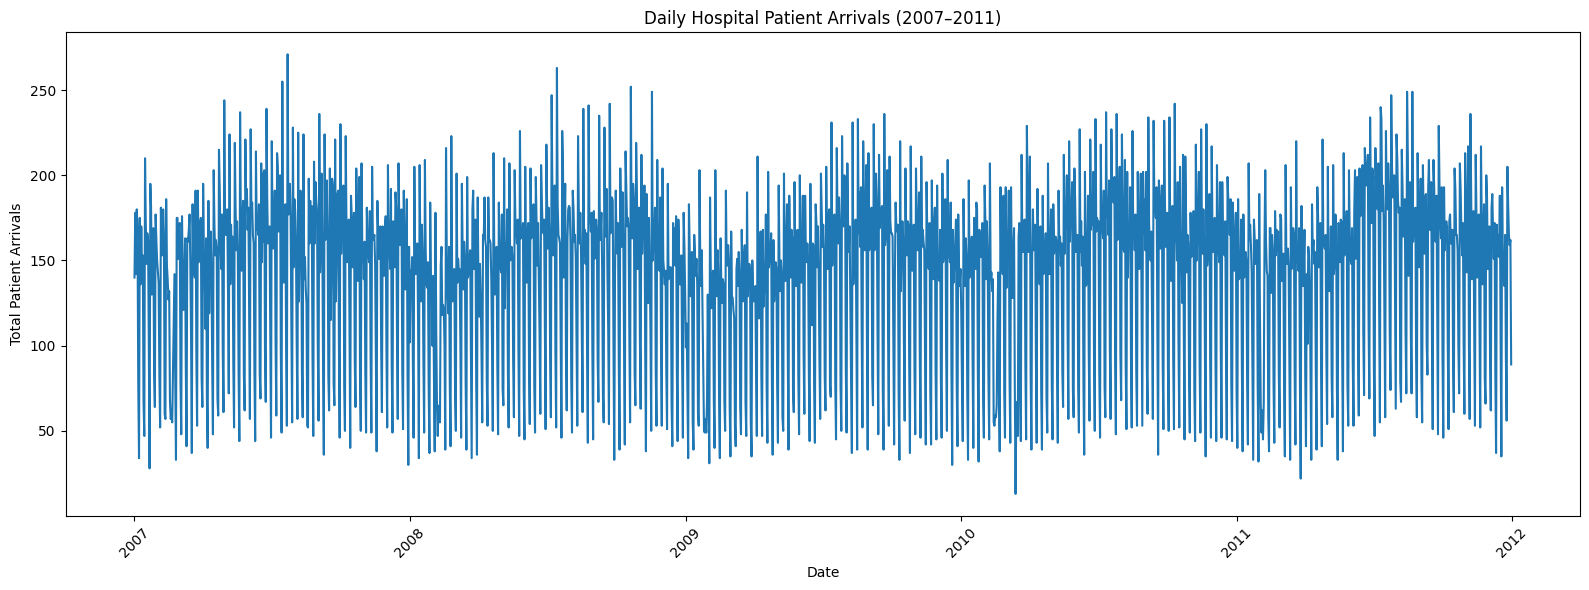

In [30]:
plt.figure(figsize=(16, 6))

plt.plot(
    final_df["Date"],
    final_df["Total_Patient_Count"]
)

plt.title("Daily Hospital Patient Arrivals (2007–2011)")
plt.xlabel("Date")
plt.ylabel("Total Patient Arrivals")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

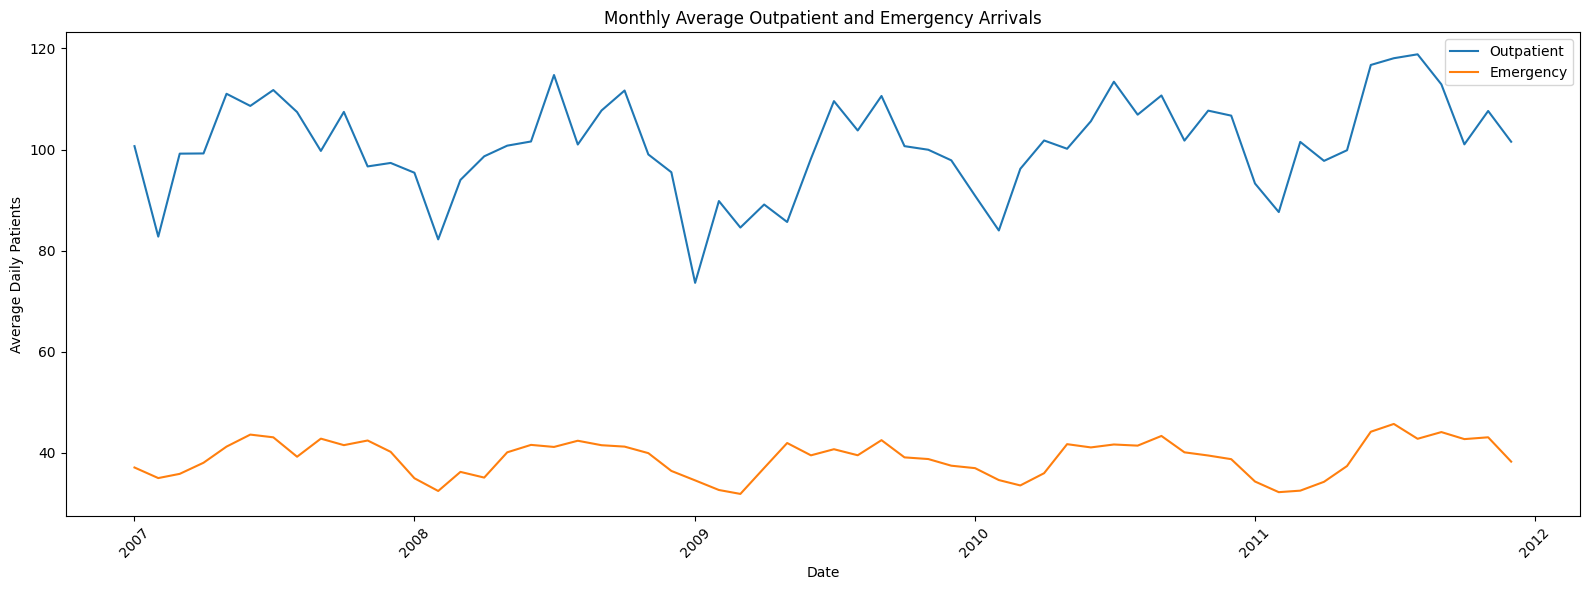

In [31]:
monthly_patient = (
    final_df
    .groupby(["Year", "Month"])[
        ["Outpatient_Count", "Emergency_Count"]
    ]
    .mean()
    .reset_index()
)

monthly_patient["Date"] = pd.to_datetime(
    monthly_patient["Year"].astype(str)
    + "-"
    + monthly_patient["Month"].astype(str)
    + "-01"
)

plt.figure(figsize=(16, 6))

plt.plot(
    monthly_patient["Date"],
    monthly_patient["Outpatient_Count"],
    label="Outpatient"
)

plt.plot(
    monthly_patient["Date"],
    monthly_patient["Emergency_Count"],
    label="Emergency"
)

plt.title("Monthly Average Outpatient and Emergency Arrivals")
plt.xlabel("Date")
plt.ylabel("Average Daily Patients")
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

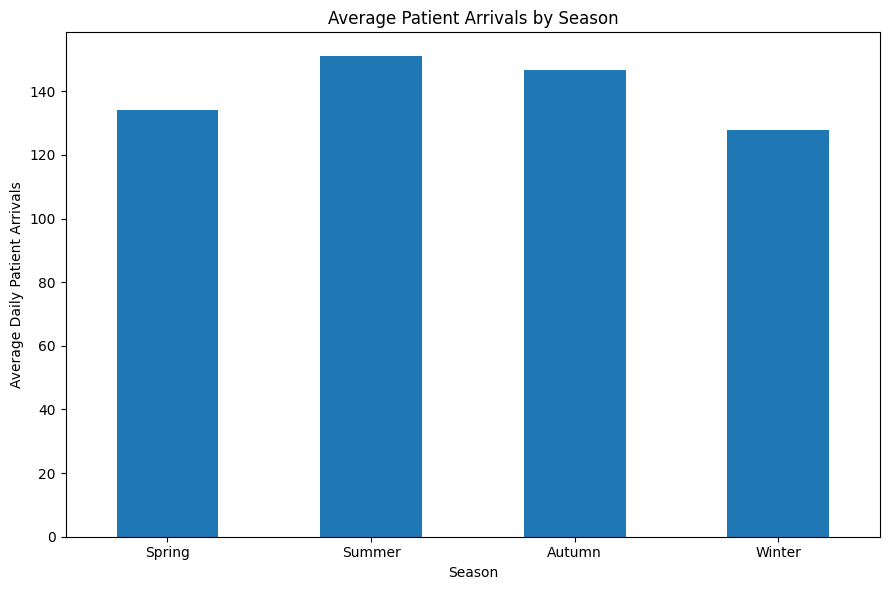

In [32]:
season_order = [
    "Spring",
    "Summer",
    "Autumn",
    "Winter"
]

seasonal_patients = (
    final_df
    .groupby("Season")["Total_Patient_Count"]
    .mean()
    .reindex(season_order)
)

plt.figure(figsize=(9, 6))

seasonal_patients.plot(kind="bar")

plt.title("Average Patient Arrivals by Season")
plt.xlabel("Season")
plt.ylabel("Average Daily Patient Arrivals")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

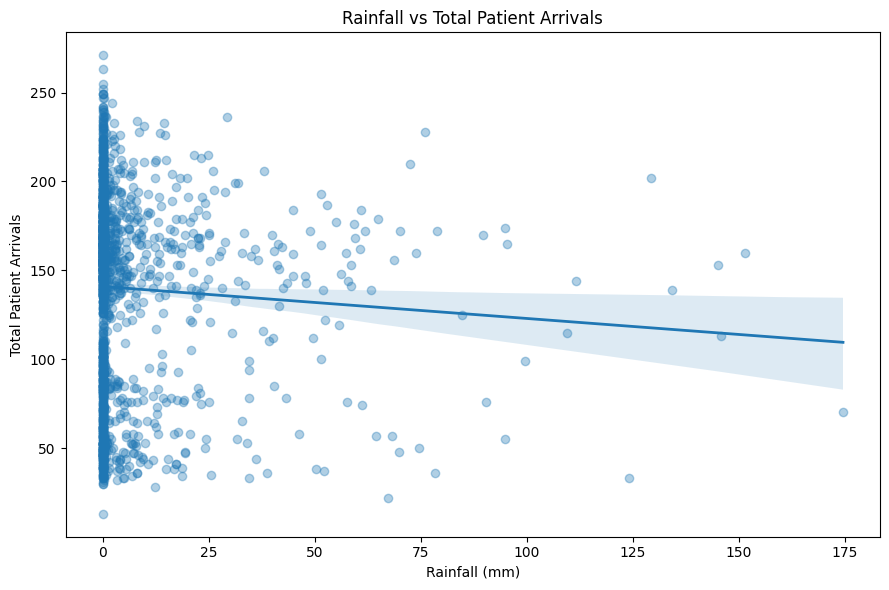

In [37]:
plt.figure(figsize=(9, 6))

sns.regplot(
    data=final_df,
    x="Rainfall_mm",
    y="Total_Patient_Count",
    scatter_kws={"alpha": 0.35},
    line_kws={"linewidth": 2}
)

plt.title("Rainfall vs Total Patient Arrivals")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Total Patient Arrivals")

plt.tight_layout()
plt.show()

In [39]:
patient_counts = [
    "Outpatient_Count",
    "Emergency_Count",
    "Total_Patient_Count"
]

weather_vars = [
    "Temperature_C",
    "Rainfall_mm",
    "Humidity_pct",
    "Wind_Speed_mps",
    "Wind_Direction_deg"
]

air_quality_vars = [
    "PM10_ug_m3",
    "PM25_ug_m3",
    "CO_ppmv",
    "NO_ppbv",
    "NO2_ppbv",
    "O3_ppbv",
    "SO2_ppbv"
]

age_group_vars = [
    "Age_0_15_Count",
    "Age_16_65_Count",
    "Age_65plus_Count"
]


def calculate_and_print_correlations(df, feature_list, target_list):
    results = []
    for target in target_list:
        for feature in feature_list:
            correlation, p_value = pearsonr(df[feature], df[target])
            results.append({
                "Target": target,
                "Feature": feature,
                "Pearson_Correlation": correlation,
                "P_Value": p_value
            })
    return pd.DataFrame(results)


print("\n--- Weather vs. Patient Arrivals ---")
weather_correlations = calculate_and_print_correlations(
    final_df,
    weather_vars,
    patient_counts
)
display(weather_correlations)

print("\n--- Air Quality vs. Patient Arrivals ---")
air_quality_correlations = calculate_and_print_correlations(
    final_df,
    air_quality_vars,
    patient_counts
)
display(air_quality_correlations)

print("\n--- Age Group vs. Total Patient Arrivals ---")
age_group_correlations = calculate_and_print_correlations(
    final_df,
    age_group_vars,
    ["Total_Patient_Count"]
)
display(age_group_correlations)



--- Weather vs. Patient Arrivals ---


,Target,Feature,Pearson_Correlation,P_Value
0,Outpatient_Count,Temperature_C,0.114550,9.213014e-07
1,Outpatient_Count,Rainfall_mm,-0.038066,1.039283e-01
2,Outpatient_Count,Humidity_pct,0.009689,6.790611e-01
3,Outpatient_Count,Wind_Speed_mps,-0.019395,4.075105e-01
4,Outpatient_Count,Wind_Direction_deg,-0.018601,4.269744e-01
5,Emergency_Count,Temperature_C,0.357321,4.109229e-56
6,Emergency_Count,Rainfall_mm,-0.073097,1.774363e-03
7,Emergency_Count,Humidity_pct,-0.072176,2.027997e-03
8,Emergency_Count,Wind_Speed_mps,-0.002840,9.034788e-01
9,Emergency_Count,Wind_Direction_deg,0.142981,8.399045e-10



--- Air Quality vs. Patient Arrivals ---


,Target,Feature,Pearson_Correlation,P_Value
0,Outpatient_Count,PM10_ug_m3,-0.030609,1.910881e-01
1,Outpatient_Count,PM25_ug_m3,0.024014,3.050877e-01
2,Outpatient_Count,CO_ppmv,0.168187,4.704490e-13
3,Outpatient_Count,NO_ppbv,0.163915,1.824501e-12
4,Outpatient_Count,NO2_ppbv,0.132902,1.194182e-08
5,Outpatient_Count,O3_ppbv,0.028016,2.314742e-01
6,Outpatient_Count,SO2_ppbv,0.133940,9.167444e-09
7,Emergency_Count,PM10_ug_m3,-0.044310,5.834842e-02
8,Emergency_Count,PM25_ug_m3,-0.022868,3.287488e-01
9,Emergency_Count,CO_ppmv,-0.012641,5.893317e-01



--- Age Group vs. Total Patient Arrivals ---


,Target,Feature,Pearson_Correlation,P_Value
0,Total_Patient_Count,Age_0_15_Count,0.878139,0.0
1,Total_Patient_Count,Age_16_65_Count,0.982422,0.0
2,Total_Patient_Count,Age_65plus_Count,0.808161,0.0


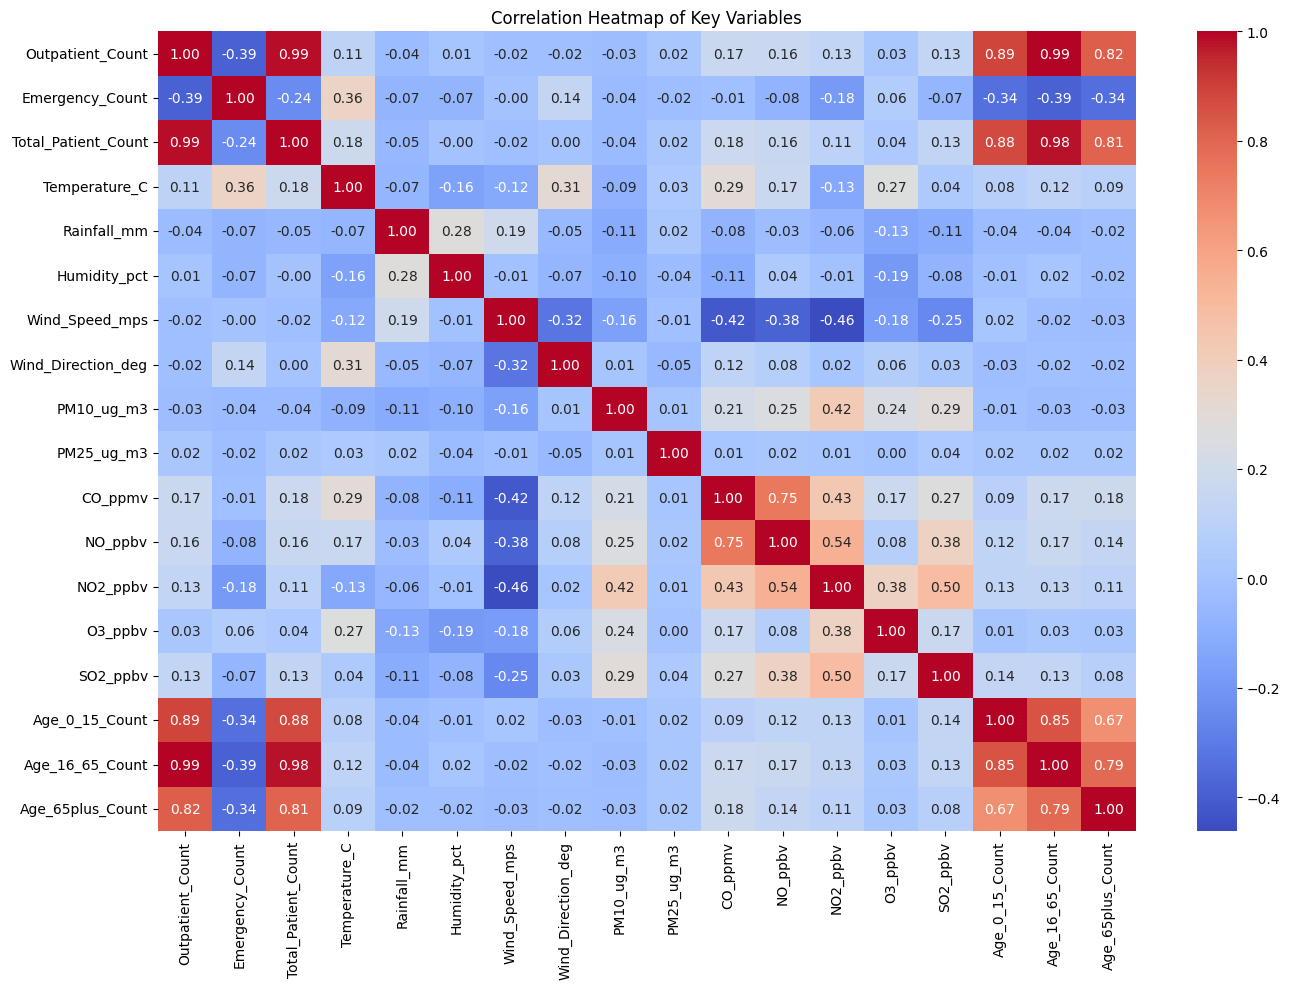

In [40]:
correlation_cols = (
    patient_counts
    + weather_vars
    + air_quality_vars
    + age_group_vars
)

plt.figure(figsize=(14, 10))
sns.heatmap(
    final_df[correlation_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap of Key Variables")
plt.tight_layout()
plt.show()


In [42]:
# Sort data by Date to ensure a time-based split
final_df = final_df.sort_values(by="Date")

# Define the split point (e.g., 80% for training)
split_point = int(len(final_df) * 0.8)

# Split into training and testing sets
train_df = final_df.iloc[:split_point]
test_df = final_df.iloc[split_point:]

print(f"Training set size: {len(train_df)}")
print(f"Testing set size: {len(test_df)}")
print(f"Training date range: {train_df['Date'].min()} to {train_df['Date'].max()}")
print(f"Testing date range: {test_df['Date'].min()} to {test_df['Date'].max()}")

Training set size: 1460
Testing set size: 366
Training date range: 2007-01-01 00:00:00 to 2010-12-30 00:00:00
Testing date range: 2010-12-31 00:00:00 to 2011-12-31 00:00:00


In [43]:
# Select features (X) and target (y)
features = [
    "Temperature_C",
    "Rainfall_mm",
    "Humidity_pct",
    "Wind_Speed_mps",
    "PM10_ug_m3",
    "PM25_ug_m3",
    "CO_ppmv",
    "NO_ppbv",
    "NO2_ppbv",
    "O3_ppbv",
    "SO2_ppbv",
    "Day",
    "Month",
    "Year",
    "Day_of_Week_Num",
    "Extreme_Temperature",
    "Heavy_Rain",
    "Extreme_Humidity"
]
target = "Total_Patient_Count"

X_train = train_df[features]
y_train = train_df[target]
X_test = test_df[features]
y_test = test_df[target]

# Scale numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Features selected and scaled successfully!")

Features selected and scaled successfully!


In [44]:
# Initialize and train the Linear Regression model
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test_scaled)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R2): {r2:.2f}")

# Display coefficients
coefficients_df = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_
})
display(coefficients_df.sort_values(by="Coefficient", ascending=False))

Mean Absolute Error (MAE): 24.12
Mean Squared Error (MSE): 999.60
Root Mean Squared Error (RMSE): 31.62
R-squared (R2): 0.65


,Feature,Coefficient
0,Temperature_C,8.965422
8,NO2_ppbv,4.702422
12,Month,4.562511
10,SO2_ppbv,2.490786
3,Wind_Speed_mps,2.437140
2,Humidity_pct,1.758640
7,NO_ppbv,1.081560
15,Extreme_Temperature,0.967220
11,Day,0.733630
6,CO_ppmv,0.667803


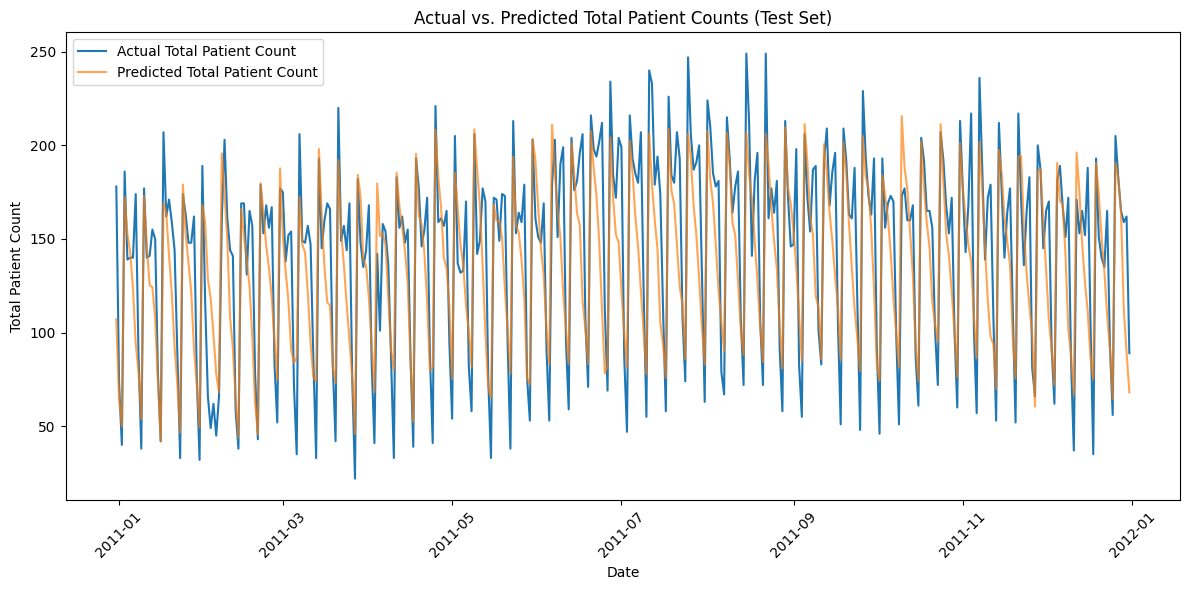

In [46]:
plt.figure(figsize=(12, 6))
plt.plot(test_df["Date"], y_test, label="Actual Total Patient Count")
plt.plot(test_df["Date"], y_pred, label="Predicted Total Patient Count", alpha=0.7)
plt.title("Actual vs. Predicted Total Patient Counts (Test Set)")
plt.xlabel("Date")
plt.ylabel("Total Patient Count")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()